# Resizing the original images and converting them into a numpy array

In [13]:
from PIL import Image
import os
import time
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from pathlib import Path
import cv2
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.image as mpimg

root = Path.cwd().parents[0]
data_dir = root / "data" / "raw" / "BrainScan_Dataset"

data = []

for folder in data_dir.iterdir():
    for img in folder.iterdir():
        image = cv2.imread(img)
        image = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
        resized_img = cv2.resize(image,(224,224),interpolation=cv2.INTER_AREA)
        row = {
            "Image_Array":resized_img,
            "Class":folder.name
        }
        data.append(row)

df = pd.DataFrame(data)

display(df)
print(type(df["Image_Array"].iloc[0]))
print(df["Image_Array"].iloc[0].shape)

,Image_Array,Class
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,...",glioma
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",glioma
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",glioma
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",glioma
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",glioma
...,...,...
7018,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",notumor
7019,"[[12, 13, 14, 13, 12, 13, 14, 15, 16, 16, 16, ...",notumor
7020,"[[3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1, 1, 2, 2, 2,...",notumor
7021,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",notumor


<class 'numpy.ndarray'>
(224, 224)


# Encoding Labels

In [14]:
mapped = {
    "glioma":0,
    "meningioma":1,
    "notumor":2,
    "pituitary":3
}

df["Class"] = df["Class"].map(mapped)

display(df)

,Image_Array,Class
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,...",0
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0
...,...,...
7018,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2
7019,"[[12, 13, 14, 13, 12, 13, 14, 15, 16, 16, 16, ...",2
7020,"[[3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1, 1, 2, 2, 2,...",2
7021,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2


# Normalizing and defining X and y

In [15]:
X = np.stack(df["Image_Array"].to_numpy())

X = X.astype(np.float32)/255.0
y = df["Class"].to_numpy()

np.savez_compressed(
    f"{root}/data/processed/brainscan_processed.npz",
    X=X,
    y=y
)


# Splitting training and testing sets

In [16]:
X_dev , X_test , y_dev , y_test = train_test_split(
    X,
    y,
    test_size = 0.15,
    random_state = 42,
    stratify = y
)

X_train , X_val , y_train , y_val = train_test_split(
    X_dev,
    y_dev,
    test_size = 0.15 / 0.85,
    random_state = 42,
    stratify = y_dev
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

Training: (4915, 224, 224) (4915,)
Validation: (1054, 224, 224) (1054,)
Test: (1054, 224, 224) (1054,)


# Building CNN architecture

In [17]:
num_classes = 4

model = keras.Sequential([
    keras.Input(shape=X_train.shape[1:]),

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Dropout(0.25),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation="softmax")
])

# Compile the model with Adam and the correct loss

In [18]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect model.summary()

In [19]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,572 (98.07 MB)

 Trainable params: 25,709,572 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

# Plot the model architecture with plot_model()

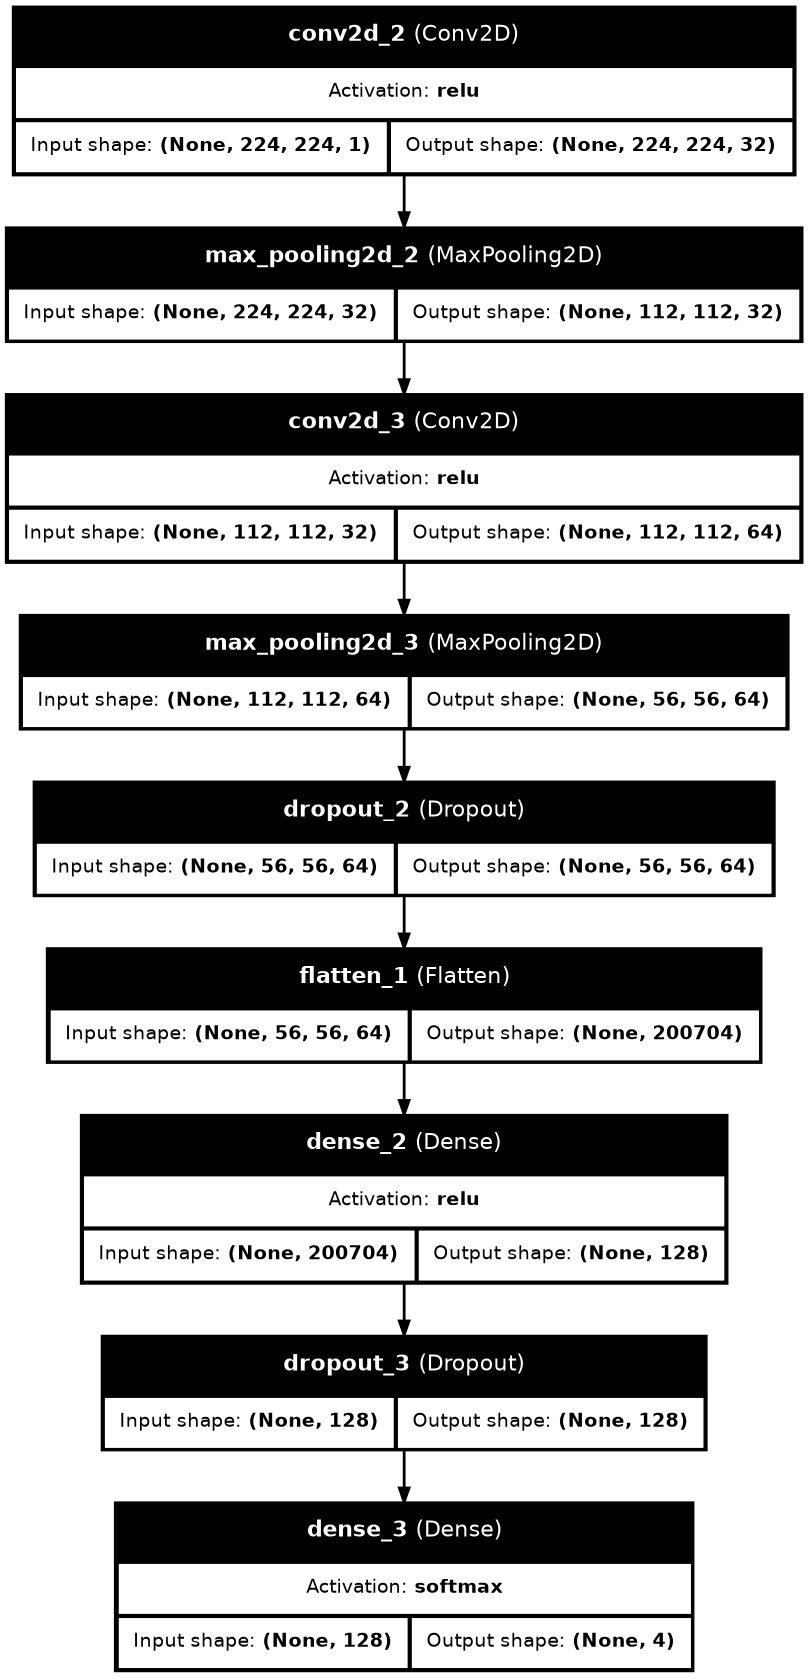

In [20]:
plot_model(
    model,
    to_file="brainscan_cnn.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=100
)

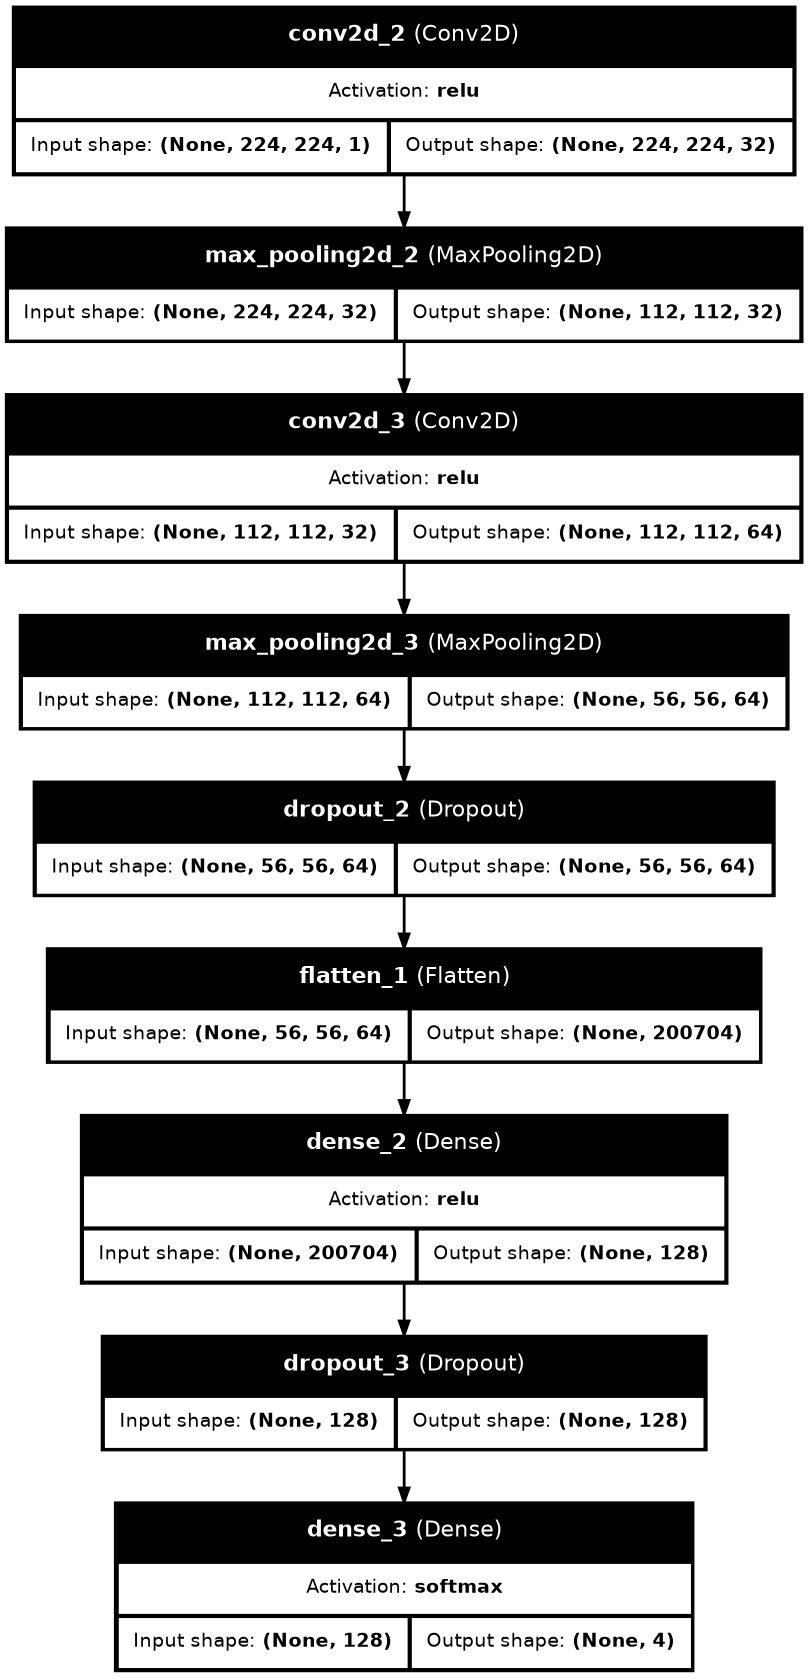

In [21]:
from IPython.display import Image, display

display(Image(filename="brainscan_cnn.png"))

# Verify the acceptance criteria

In [22]:
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of classes:", num_classes)
print("Optimizer:", model.optimizer.__class__.__name__)
print("Loss function:", model.loss)

Input shape: (None, 224, 224, 1)
Output shape: (None, 4)
Number of classes: 4
Optimizer: Adam
Loss function: sparse_categorical_crossentropy


# Define your hyperparameters

In [23]:
BATCH_SIZE = 8
EPOCHS = 30
LEARNING_RATE = 0.001

OUTPUT_DIR = f"{root}/reports/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Epochs: 30
Batch size: 8
Learning rate: 0.001


# Configure ModelCheckpoint and EarlyStopping

In [24]:
checkpoint_path = root / "models" /"best_brainscan_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        str(f"{OUTPUT_DIR}/training_log.csv")
    )
]

# Train the CNN and measure the duration

In [25]:
start_time = time.perf_counter()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

training_seconds = time.perf_counter() - start_time

print(f"Training time: {training_seconds / 60:.2f} minutes")

Epoch 1/30
615/615 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.7257 - loss: 0.7110  
Epoch 1: val_loss improved from None to 0.42682, saving model to /home/walid/Documents/BrainScan/models/best_brainscan_cnn.keras

Epoch 1: finished saving model to /home/walid/Documents/BrainScan/models/best_brainscan_cnn.keras
615/615 ━━━━━━━━━━━━━━━━━━━━ 218s 351ms/step - accuracy: 0.7257 - loss: 0.7110 - val_accuracy: 0.8463 - val_loss: 0.4268
Epoch 2/30
615/615 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.8623 - loss: 0.3550  
Epoch 2: val_loss improved from 0.42682 to 0.31275, saving model to /home/walid/Documents/BrainScan/models/best_brainscan_cnn.keras

Epoch 2: finished saving model to /home/walid/Documents/BrainScan/models/best_brainscan_cnn.keras
615/615 ━━━━━━━━━━━━━━━━━━━━ 213s 346ms/step - accuracy: 0.8623 - loss: 0.3550 - val_accuracy: 0.8852 - val_loss: 0.3128
Epoch 3/30
615/615 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.9152 - loss: 0.2287  
Epoch 3: val_loss improved fr

# Check the training and validation metrics

In [26]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

probabilities = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

predictions = np.argmax(probabilities, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=np.arange(4),
    target_names=["glioma", "meningioma", "notumor", "pituitary"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    predictions,
    labels=np.arange(4)
))

132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.9269 - loss: 0.1856
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step
Test loss: 0.1856
Test accuracy: 0.9269

Classification report:
              precision    recall  f1-score   support

      glioma       0.91      0.90      0.90       243
  meningioma       0.86      0.85      0.85       247
     notumor       0.98      0.97      0.97       300
   pituitary       0.94      0.98      0.96       264

    accuracy                           0.93      1054
   macro avg       0.92      0.92      0.92      1054
weighted avg       0.93      0.93      0.93      1054

Confusion matrix:
[[219  24   0   0]
 [ 20 209   5  13]
 [  1   5 290   4]
 [  1   4   0 259]]


# Plot the training curves

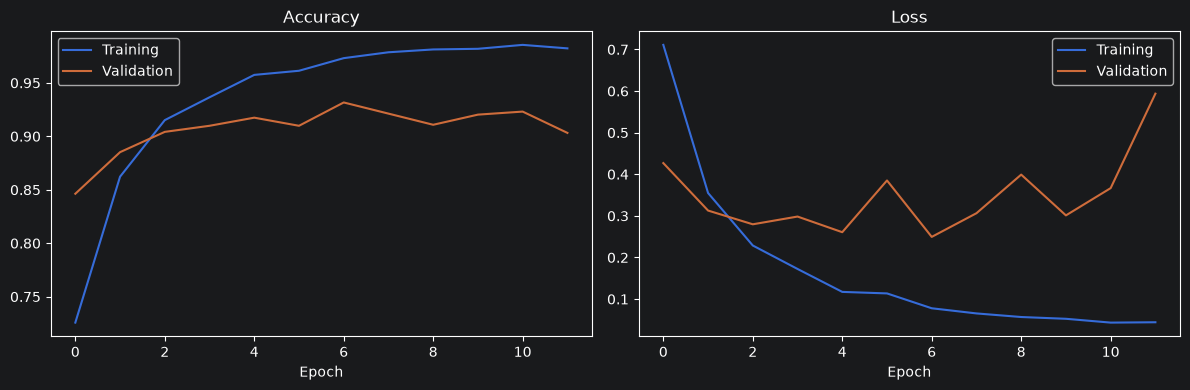

Training complete.
Best checkpoint: /home/walid/Documents/BrainScan/models/best_brainscan_cnn.keras
Outputs saved in: /home/walid/Documents/BrainScan/reports/


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}learning_curves.png", dpi=150)
plt.show()

print("Training complete.")
print("Best checkpoint:", checkpoint_path)
print("Outputs saved in:", OUTPUT_DIR)